<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp27.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 27: Deep Belief Network Representation Learning

**Category**: CO5 – Energy-Based and Generative Models  
**Objective**: Perform layer-wise unsupervised greedy pretraining of stacked RBMs to learn hierarchical latent feature representations.


### Task 1: Greedy Layer-Wise Pretraining of Stacked RBMs (Deep Belief Net)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# Load digits dataset as binary image vectors (8x8 = 64 inputs)
digits = load_digits()
X_digits = (digits.data > 8).astype(float) # Binarized 64-dim inputs
y_labels = digits.target

n_in, n_h1, n_h2 = 64, 32, 16

def train_rbm_layer(X, n_vis, n_hid, lr=0.05, epochs=35):
    np.random.seed(42)
    W = np.random.randn(n_vis, n_hid) * 0.1
    b_v = np.zeros(n_vis)
    b_h = np.zeros(n_hid)
    N = len(X)
    for _ in range(epochs):
        # Positive
        p_h0 = 1.0 / (1.0 + np.exp(-np.clip(np.dot(X, W) + b_h, -15, 15)))
        h0 = (np.random.rand(*p_h0.shape) < p_h0).astype(float)
        # Negative
        p_v1 = 1.0 / (1.0 + np.exp(-np.clip(np.dot(h0, W.T) + b_v, -15, 15)))
        p_h1 = 1.0 / (1.0 + np.exp(-np.clip(np.dot(p_v1, W) + b_h, -15, 15)))
        # Update
        W += lr * (np.dot(X.T, p_h0) - np.dot(p_v1.T, p_h1)) / N
        b_v += lr * np.mean(X - p_v1, axis=0)
        b_h += lr * np.mean(p_h0 - p_h1, axis=0)
    return W, b_h

print("Training DBN Layer 1 (64 -> 32)...")
W1, b1 = train_rbm_layer(X_digits, n_in, n_h1)

# Pass representations to Layer 2
H1 = 1.0 / (1.0 + np.exp(-np.clip(np.dot(X_digits, W1) + b1, -15, 15)))

print("Training DBN Layer 2 (32 -> 16)...")
W2, b2 = train_rbm_layer(H1, n_h1, n_h2)

# Latent code from top layer
H2 = 1.0 / (1.0 + np.exp(-np.clip(np.dot(H1, W2) + b2, -15, 15)))
print(f"Hierarchical Feature Extraction Complete. Final Representation Shape: {H2.shape}")


Training DBN Layer 1 (64 -> 32)...
Training DBN Layer 2 (32 -> 16)...
Hierarchical Feature Extraction Complete. Final Representation Shape: (1797, 16)


### Task 2: Visualize Hierarchical Latent Space Projections


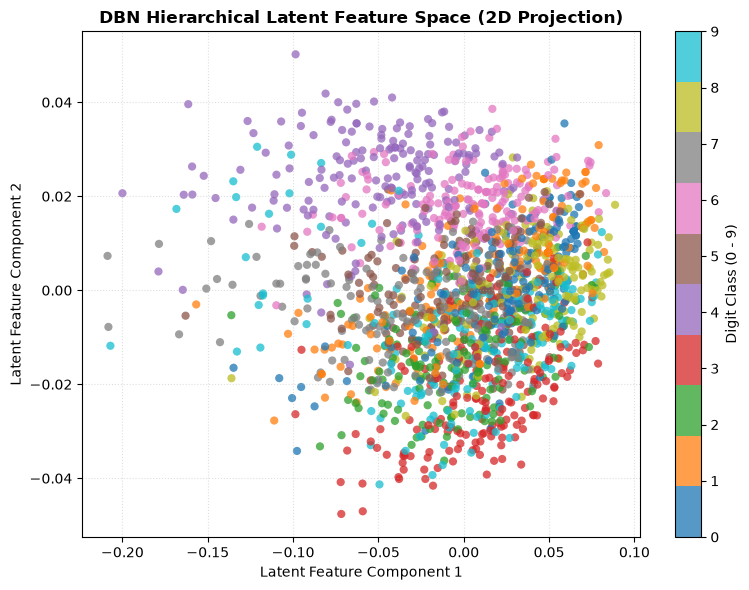

In [2]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
latent_2d = pca.fit_transform(H2)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(latent_2d[:, 0], latent_2d[:, 1], c=y_labels, cmap='tab10', alpha=0.75, s=35, edgecolors='none')
plt.colorbar(scatter, label='Digit Class (0 - 9)')
plt.title("DBN Hierarchical Latent Feature Space (2D Projection)", fontweight='bold')
plt.xlabel("Latent Feature Component 1")
plt.ylabel("Latent Feature Component 2")
plt.grid(True, linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()
